<a href="https://colab.research.google.com/github/JelyJeloJela/ComputerVision/blob/main/knntest.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Part 1: Dataset Locating and Extraction
First, we will scan Google Drive to find the exact path of the `.tar.gz` file under the `KnnTest` folder and extract it.

In [ ]:
import os
import glob

# Direct path to the extracted CIFAR-10 folder on your Google Drive
dataset_dir = "/content/drive/MyDrive/KnnTest/cifar-10-batches-py"

if os.path.exists(dataset_dir):
    print(f"Successfully found the extracted dataset directory at: {dataset_dir}")
    files = os.listdir(dataset_dir)
    print("Available batch files:", files)
else:
    print(f"Error: The directory {dataset_dir} could not be found. Please check your Drive connection.")

Successfully found the extracted dataset directory at: /content/drive/MyDrive/KnnTest/cifar-10-batches-py
Available batch files: ['test_batch', 'data_batch_3', 'data_batch_2', 'data_batch_5', 'data_batch_1', 'data_batch_4', 'batches.meta', 'readme.html']


In [ ]:
import os
import glob

knn_test_dir = "/content/drive/MyDrive/KnnTest"
if os.path.exists(knn_test_dir):
    print(f"Contents of {knn_test_dir}:")
    for root, dirs, files in os.walk(knn_test_dir):
        level = root.replace(knn_test_dir, '').count(os.sep)
        indent = ' ' * 4 * (level)
        print(f"{indent}[Dir] {os.path.basename(root)}/")
        subindent = ' ' * 4 * (level + 1)
        for f in files:
            print(f"{subindent}{f}")
else:
    print(f"{knn_test_dir} does not exist. Let's list '/content/drive/MyDrive' to see where it is:")
    print(os.listdir('/content/drive/MyDrive'))

Contents of /content/drive/MyDrive/KnnTest:
[Dir] KnnTest/
    cifar-10-python.tar.gz
    [Dir] cifar-10-batches-py/
        test_batch
        data_batch_3
        data_batch_2
        data_batch_5
        data_batch_1
        data_batch_4
        batches.meta
        readme.html


# Part 2: Loading CIFAR-10 Data
Flatten 32x32x3 matrix into a 2D Vector

In [ ]:
import os
import pickle
import numpy as np

def load_batch(file_path):
    with open(file_path, 'rb') as f:
        datadict = pickle.load(f, encoding='bytes')
        X = datadict[b'data']
        Y = datadict[b'labels']
        X = X.reshape(10000, 3, 32, 32).transpose(0, 2, 3, 1).astype("float32")
        Y = np.array(Y)
        return X, Y

# Direct path to your Google Drive CIFAR-10 folder
root_dir = "/content/drive/MyDrive/KnnTest/cifar-10-batches-py"

if os.path.exists(root_dir):
    print(f"Loading CIFAR-10 from: {root_dir}")

    # Load all training batches
    xs, ys = [] , []
    for i in range(1, 6):
        f = os.path.join(root_dir, f'data_batch_{i}')
        X, Y = load_batch(f)
        xs.append(X)
        ys.append(Y)

    X_train = np.concatenate(xs)
    y_train = np.concatenate(ys)
    X_test, y_test = load_batch(os.path.join(root_dir, 'test_batch'))

    # Flatten images to vectors for KNN
    X_train_flat = X_train.reshape(X_train.shape[0], -1)
    X_test_flat = X_test.reshape(X_test.shape[0], -1)

    print(f"Train data shape: {X_train_flat.shape}")
    print(f"Test data shape: {X_test_flat.shape}")
else:
    print(f"Could not locate dataset folder at: {root_dir}")

Loading CIFAR-10 from: /content/drive/MyDrive/KnnTest/cifar-10-batches-py
Train data shape: (50000, 3072)
Test data shape: (10000, 3072)


In [ ]:
X_train_sub = X_train_flat[:5000]
y_train_sub = y_train[:5000]
X_val_sub = X_test_flat[:500]
y_val_sub = y_test[:500]

print("Data subsampled successfully.")
print("Train shape:", X_train_sub.shape)
print("Validation/Test shape:", X_val_sub.shape)

Data subsampled successfully.
Train shape: (5000, 3072)
Validation/Test shape: (500, 3072)


In [ ]:
# Part 3: KNN Implementation and Evaluation

In [ ]:
from collections import Counter
import numpy as np

class KNNClassifier:
    def __init__(self, k=3, metric='l2'):
        self.k = k
        self.metric = metric

    def fit(self, X, y):
        self.X_train = X
        self.y_train = y

    def predict(self, X):
        predictions = []
        for x in X:
            if self.metric == 'l2':
                distances = np.sqrt(np.sum((self.X_train - x) ** 2, axis=1))
            elif self.metric == 'l1':
                distances = np.sum(np.abs(self.X_train - x), axis=1)
            else:
                raise ValueError("Unknown metric. Use 'l1' or 'l2'")

            # Get indices of k smallest distances
            k_indices = np.argsort(distances)[:self.k]
            k_nearest_labels = self.y_train[k_indices]

            # Majority vote
            most_common = Counter(k_nearest_labels).most_common(1)
            predictions.append(most_common[0][0])
        return np.array(predictions)

print("KNNClassifier class defined successfully.")

KNNClassifier class defined successfully.


# Part 4: 5-Fold Cross-Validation
We perform 5-fold cross validation on our training subset to find the best `k` and distance metric.

In [ ]:
from sklearn.metrics import accuracy_score

num_folds = 5
k_choices = [1, 3, 5, 10]
metrics = ['l1', 'l2']

# Split training subset into folds
X_folds = np.array_split(X_train_sub, num_folds)
y_folds = np.array_split(y_train_sub, num_folds)

results = {}

print("Starting 5-Fold Cross-Validation...")
for metric in metrics:
    for k in k_choices:
        fold_accuracies = []
        for i in range(num_folds):
            X_val_fold = X_folds[i]
            y_val_fold = y_folds[i]

            X_train_fold = np.concatenate([X_folds[j] for j in range(num_folds) if j != i])
            y_train_fold = np.concatenate([y_folds[j] for j in range(num_folds) if j != i])

            knn = KNNClassifier(k=k, metric=metric)
            knn.fit(X_train_fold, y_train_fold)
            y_pred = knn.predict(X_val_fold)

            acc = accuracy_score(y_val_fold, y_pred)
            fold_accuracies.append(acc)

        results[(metric, k)] = np.mean(fold_accuracies)
        print(f"Metric: {metric}, K: {k} -> Mean Validation Accuracy: {results[(metric, k)]:.4f}")

Starting 5-Fold Cross-Validation...
Metric: l1, K: 1 -> Mean Validation Accuracy: 0.2962
Metric: l1, K: 3 -> Mean Validation Accuracy: 0.3050
Metric: l1, K: 5 -> Mean Validation Accuracy: 0.3142
Metric: l1, K: 10 -> Mean Validation Accuracy: 0.3250
Metric: l2, K: 1 -> Mean Validation Accuracy: 0.2656
Metric: l2, K: 3 -> Mean Validation Accuracy: 0.2690
Metric: l2, K: 5 -> Mean Validation Accuracy: 0.2834
Metric: l2, K: 10 -> Mean Validation Accuracy: 0.2882


# Part 5: Evaluation & Comparison on Test Set
Finally, we evaluate the best model on the test dataset and compute performance metrics including Precision, Recall, and F1-score.

In [ ]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

# Identify best hyperparameters
best_config = max(results, key=results.get)
best_metric, best_k = best_config
print(f"Best configuration found: Metric={best_metric}, K={best_k}\n")

# Train best model on all subsampled train data and evaluate on validation/test set
best_knn = KNNClassifier(k=best_k, metric=best_metric)
best_knn.fit(X_train_sub, y_train_sub)
y_pred_test = best_knn.predict(X_val_sub)

accuracy = accuracy_score(y_val_sub, y_pred_test)
precision, recall, f1, _ = precision_recall_fscore_support(y_val_sub, y_pred_test, average='macro')

print("=== FINAL EVALUATION METRICS ===")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1:.4f}")

Best configuration found: Metric=l1, K=10

=== FINAL EVALUATION METRICS ===
Accuracy:  0.2900
Precision: 0.3705
Recall:    0.2778
F1-Score:  0.2584


### Part 6: Visualizing Classification Results and KNN Scatter Plot
Here we visually inspect our model's performance on the dataset by displaying sample predictions, and we generate a 2D scatter plot using t-SNE to visualize how the KNN classification clusters the image vectors.

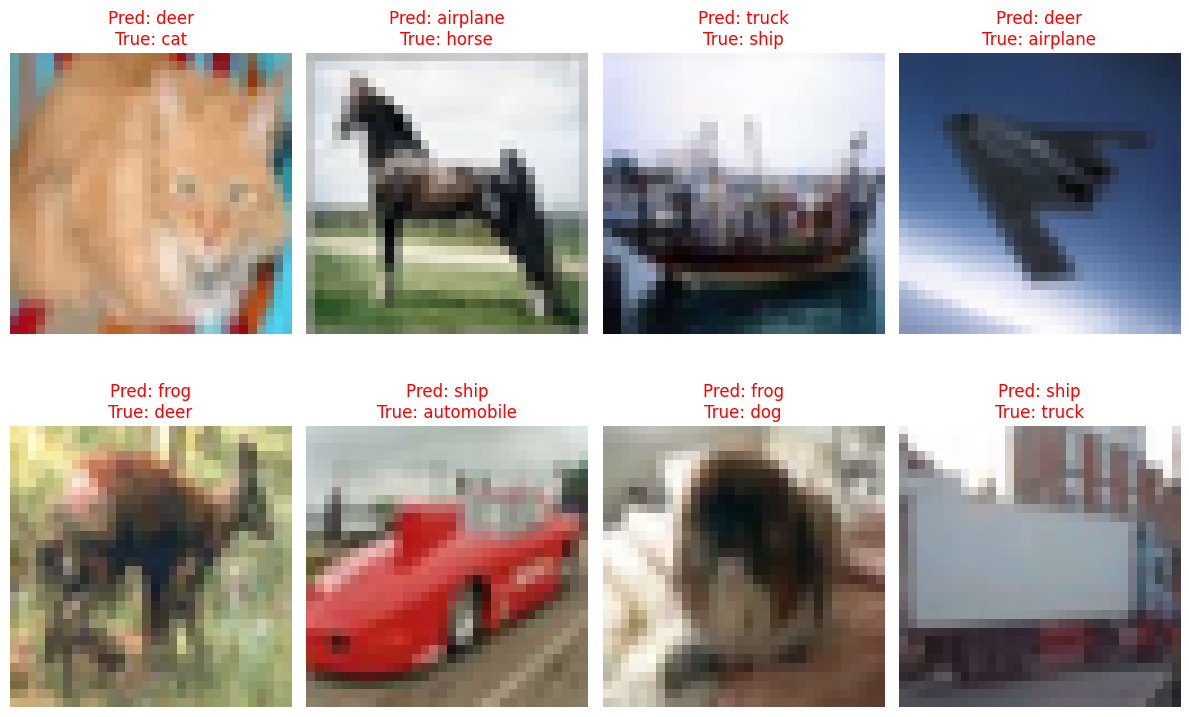

In [ ]:
import matplotlib.pyplot as plt

# Map CIFAR-10 numeric labels to class names
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

# Reshape validation subset back to 32x32x3 images for plotting
X_val_images = X_val_sub.reshape(-1, 32, 32, 3).astype('uint8')

# Plot some random validation images with predicted and actual labels
plt.figure(figsize=(12, 8))
indices = np.random.choice(len(X_val_sub), 8, replace=False)
for i, idx in enumerate(indices):
    plt.subplot(2, 4, i + 1)
    plt.imshow(X_val_images[idx])
    pred_label = class_names[y_pred_test[idx]]
    true_label = class_names[y_val_sub[idx]]
    color = 'green' if pred_label == true_label else 'red'
    plt.title(f"Pred: {pred_label}\nTrue: {true_label}", color=color)
    plt.axis('off')
plt.tight_layout()
plt.show()

Reducing dimensions using t-SNE for the KNN scatter plot...


/usr/local/lib/python3.13/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


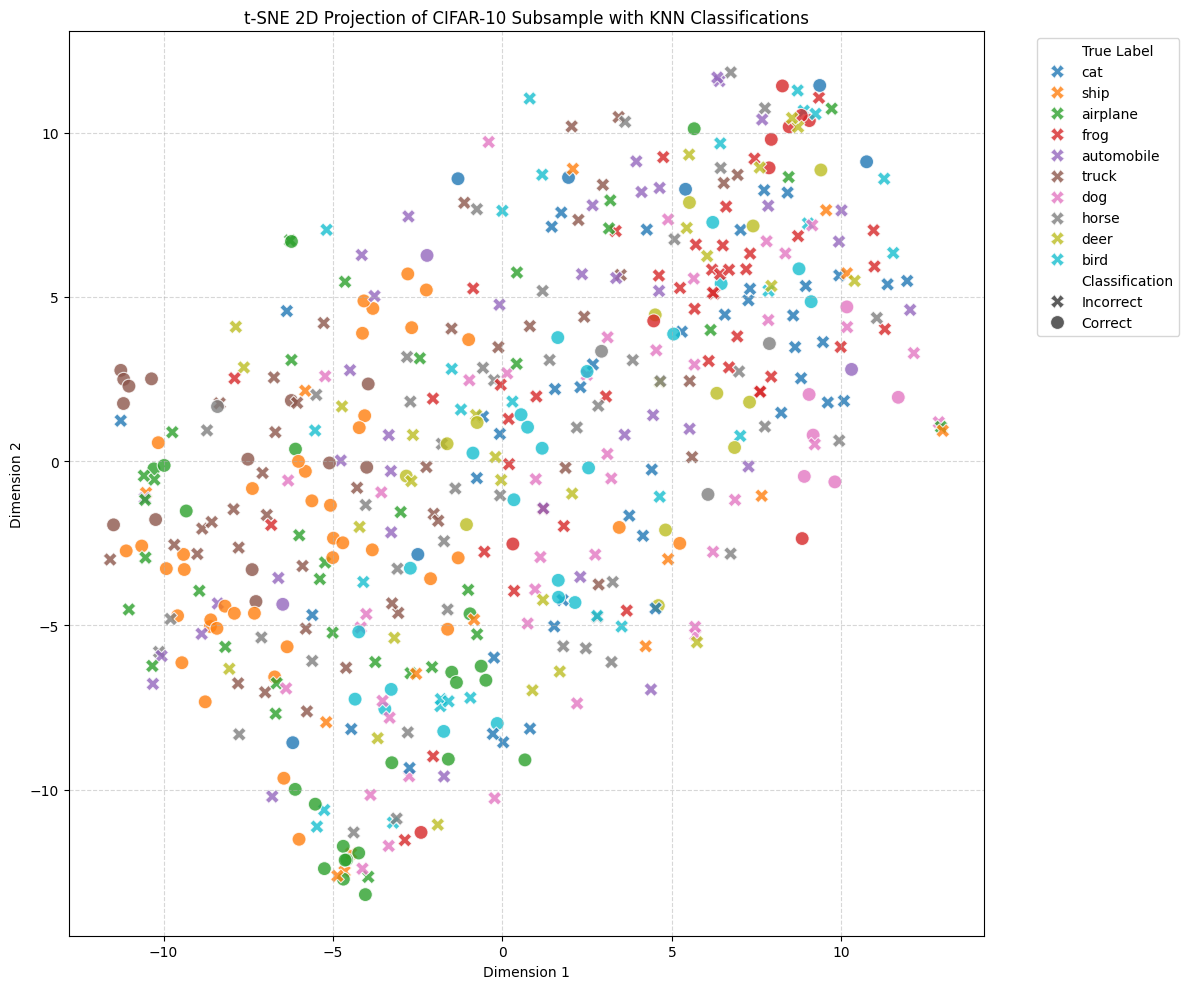

In [ ]:
from sklearn.manifold import TSNE
import pandas as pd
import seaborn as sns

print("Reducing dimensions using t-SNE for the KNN scatter plot...")
# Use t-SNE to project high-dimensional image vectors (3072 dims) to 2D
tsne = TSNE(n_components=2, random_state=42, perplexity=30, n_iter=1000)
X_val_2d = tsne.fit_transform(X_val_sub)

# Create a DataFrame for visualization
df_tsne = pd.DataFrame(X_val_2d, columns=['Dimension 1', 'Dimension 2'])
df_tsne['True Label'] = [class_names[label] for label in y_val_sub]
df_tsne['Predicted Label'] = [class_names[label] for label in y_pred_test]
df_tsne['Classification'] = np.where(y_val_sub == y_pred_test, 'Correct', 'Incorrect')

# Plot the t-SNE projection highlighting true classes and correctness
plt.figure(figsize=(12, 10))
sns.scatterplot(
    x='Dimension 1', y='Dimension 2',
    hue='True Label',
    style='Classification',
    markers={'Correct': 'o', 'Incorrect': 'X'},
    palette='tab10',
    data=df_tsne,
    alpha=0.8,
    s=100
)
plt.title('t-SNE 2D Projection of CIFAR-10 Subsample with KNN Classifications')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()